In [4]:
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

In [5]:
df=pd.read_csv("Data/variables_2024.csv")
df.head()

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Resultado financiero\nmil EUR\nÚlt. año disp.,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Ingresos extraordinarios\nmil EUR\nÚlt. año disp.,Gastos extraordinarios\nmil EUR\nÚlt. año disp.,Resultados actividades extraordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.
0,0,"VIDRALA, SA",ESPANA,2024-12-31,Sociedad anonima,Alava,LAUDIO/LLODIO,1965-03-17 00:00:00,2313,Fabricación de vidrio hueco,...,81676.0,166764.0,19799.0,146965.0,NaN,NaN,NaN,146965.0,87847.0,NaN
1,1,AERNNOVA AEROSPACE SA,ESPANA,2024-12-31,Sociedad anonima,Alava,VITORIA-GASTEIZ,1999-07-19 00:00:00,3030,Construcción aeronáutica y espacial y su maqui...,...,-33228.0,13070.0,4291.0,8779.0,NaN,NaN,NaN,8779.0,48818.0,NaN
2,3,COMPAÑIA DE BEBIDAS PEPSICO SL,ESPANA,2024-12-31,Sociedad limitada,Alava,VITORIA-GASTEIZ,1957-09-04 00:00:00,1107,Fabricación de bebidas no alcohólicas; producc...,...,-12304.0,52302.0,-10390.0,62692.0,NaN,NaN,NaN,62692.0,71344.0,NaN
3,4,ARRAIA-OIL SL,ESPANA,2024-12-31,Sociedad limitada,Alava,VITORIA-GASTEIZ,2001-01-21 00:00:00,4730,Comercio al por menor de combustible para la a...,...,-57.0,5280.0,1490.0,3790.0,NaN,NaN,NaN,3790.0,6572.0,NaN
4,6,"TUBOS REUNIDOS GROUP, S.L.",ESPANA,2024-12-31,Sociedad limitada,Alava,AMURRIO,2010-01-04 00:00:00,2420,"Fabricación de tubos, tuberías, perfiles hueco...",...,-16478.0,-12522.0,-8438.0,-4084.0,NaN,NaN,NaN,-4084.0,18930.0,NaN


In [6]:
df.shape

(26589, 50)

In [7]:
df.describe()

,index,Código primario CNAE 2009,Existencias\nmil EUR\nÚlt. año disp.,Inmovilizado\nmil EUR\nÚlt. año disp.,Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.,Inmovilizado material\nmil EUR\nÚlt. año disp.,Otros activos fijos\nmil EUR\nÚlt. año disp.,Activo circulante\nmil EUR\nÚlt. año disp.,Acreedores a L. P.\nmil EUR\nÚlt. año disp.,Deudores\nmil EUR\nÚlt. año disp.,...,Resultado financiero\nmil EUR\nÚlt. año disp.,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Ingresos extraordinarios\nmil EUR\nÚlt. año disp.,Gastos extraordinarios\nmil EUR\nÚlt. año disp.,Resultados actividades extraordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.
count,26589.000000,26589.000000,13128.000000,2.134300e+04,8.120000e+03,1.928400e+04,1.667300e+04,2.231900e+04,1.304200e+04,2.085400e+04,...,2.233000e+04,2.224000e+04,1.895900e+04,2.224100e+04,0.0,0.0,10.000000,2.224200e+04,2.226800e+04,0.0
mean,19001.831321,5345.544661,1201.248025,1.367121e+04,8.248666e+02,2.932724e+03,1.370672e+04,4.196940e+03,8.377984e+03,1.312642e+03,...,-8.573555e+01,1.287334e+03,1.845297e+01,1.271485e+03,NaN,NaN,-440.199758,1.271274e+03,1.617577e+03,NaN
std,11352.255725,1958.347544,11818.053215,5.003518e+05,1.735907e+04,1.273473e+05,5.417195e+05,5.974591e+04,3.131791e+05,2.117029e+04,...,1.057040e+04,5.175199e+04,1.088204e+04,5.117661e+04,NaN,NaN,628.086611,5.117545e+04,5.687007e+04,NaN
min,0.000000,111.000000,0.000010,-4.765660e+00,-1.003937e+03,-1.933667e+02,1.000000e-05,1.000000e-05,1.000000e-05,1.000000e-05,...,-1.293854e+06,-1.106154e+06,-1.387083e+06,-1.562320e+05,NaN,NaN,-1754.657190,-1.562320e+05,-1.384610e+05,NaN
25%,9155.000000,4322.000000,11.651625,3.135325e+01,1.573582e+00,1.521932e+01,4.400000e+00,1.143003e+02,2.410852e+01,1.708918e+01,...,-5.770600e+00,2.289918e+00,7.385900e-01,1.861460e+00,NaN,NaN,-745.042500,1.858637e+00,8.793490e+00,NaN
50%,18248.000000,4791.000000,55.369440,1.564732e+02,6.723590e+00,7.618472e+01,3.112555e+01,3.293060e+02,9.188856e+01,8.704314e+01,...,-4.262095e-01,2.911165e+01,5.323240e+00,2.502835e+01,NaN,NaN,-104.702870,2.501098e+01,4.782290e+01,NaN
75%,29283.000000,6820.000000,266.102842,7.358978e+02,3.875473e+01,3.510259e+02,2.741913e+02,1.069764e+03,3.639475e+02,3.589944e+02,...,0.000000e+00,1.359126e+02,2.410489e+01,1.158608e+02,NaN,NaN,-0.268495,1.158567e+02,1.861965e+02,NaN
max,38910.000000,9900.000000,697056.000000,5.114500e+07,1.139074e+06,1.202691e+07,5.068100e+07,5.008634e+06,2.912703e+07,1.679329e+06,...,2.638553e+05,5.472000e+06,4.440630e+05,5.652000e+06,NaN,NaN,14.896460,5.652000e+06,6.139000e+06,NaN


In [8]:
df.dtypes

index                                                                int64
Nombre                                                                 str
País                                                                   str
Ultimo año disponible                                                  str
Forma jurídica                                                         str
Provincia                                                              str
Localidad                                                              str
Fecha constitución                                                     str
Código primario CNAE 2009                                            int64
Literal código CNAE 2009 primario                                      str
Existencias\nmil EUR\nÚlt. año disp.                               float64
Inmovilizado\nmil EUR\nÚlt. año disp.                              float64
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                   float64
Inmovilizado material\nmi

In [9]:
df.isna().sum()

index                                                                  0
Nombre                                                                 0
País                                                                   0
Ultimo año disponible                                                  0
Forma jurídica                                                         0
Provincia                                                              0
Localidad                                                              1
Fecha constitución                                                     6
Código primario CNAE 2009                                              0
Literal código CNAE 2009 primario                                      0
Existencias\nmil EUR\nÚlt. año disp.                               13461
Inmovilizado\nmil EUR\nÚlt. año disp.                               5246
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                   18469
Inmovilizado material\nmil EUR\nÚlt. año disp.     

In [10]:
porcentaje=df.isna().mean()*100
print(porcentaje)

index                                                                0.000000
Nombre                                                               0.000000
País                                                                 0.000000
Ultimo año disponible                                                0.000000
Forma jurídica                                                       0.000000
Provincia                                                            0.000000
Localidad                                                            0.003761
Fecha constitución                                                   0.022566
Código primario CNAE 2009                                            0.000000
Literal código CNAE 2009 primario                                    0.000000
Existencias\nmil EUR\nÚlt. año disp.                                50.626199
Inmovilizado\nmil EUR\nÚlt. año disp.                               19.729964
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                

<Axes: >

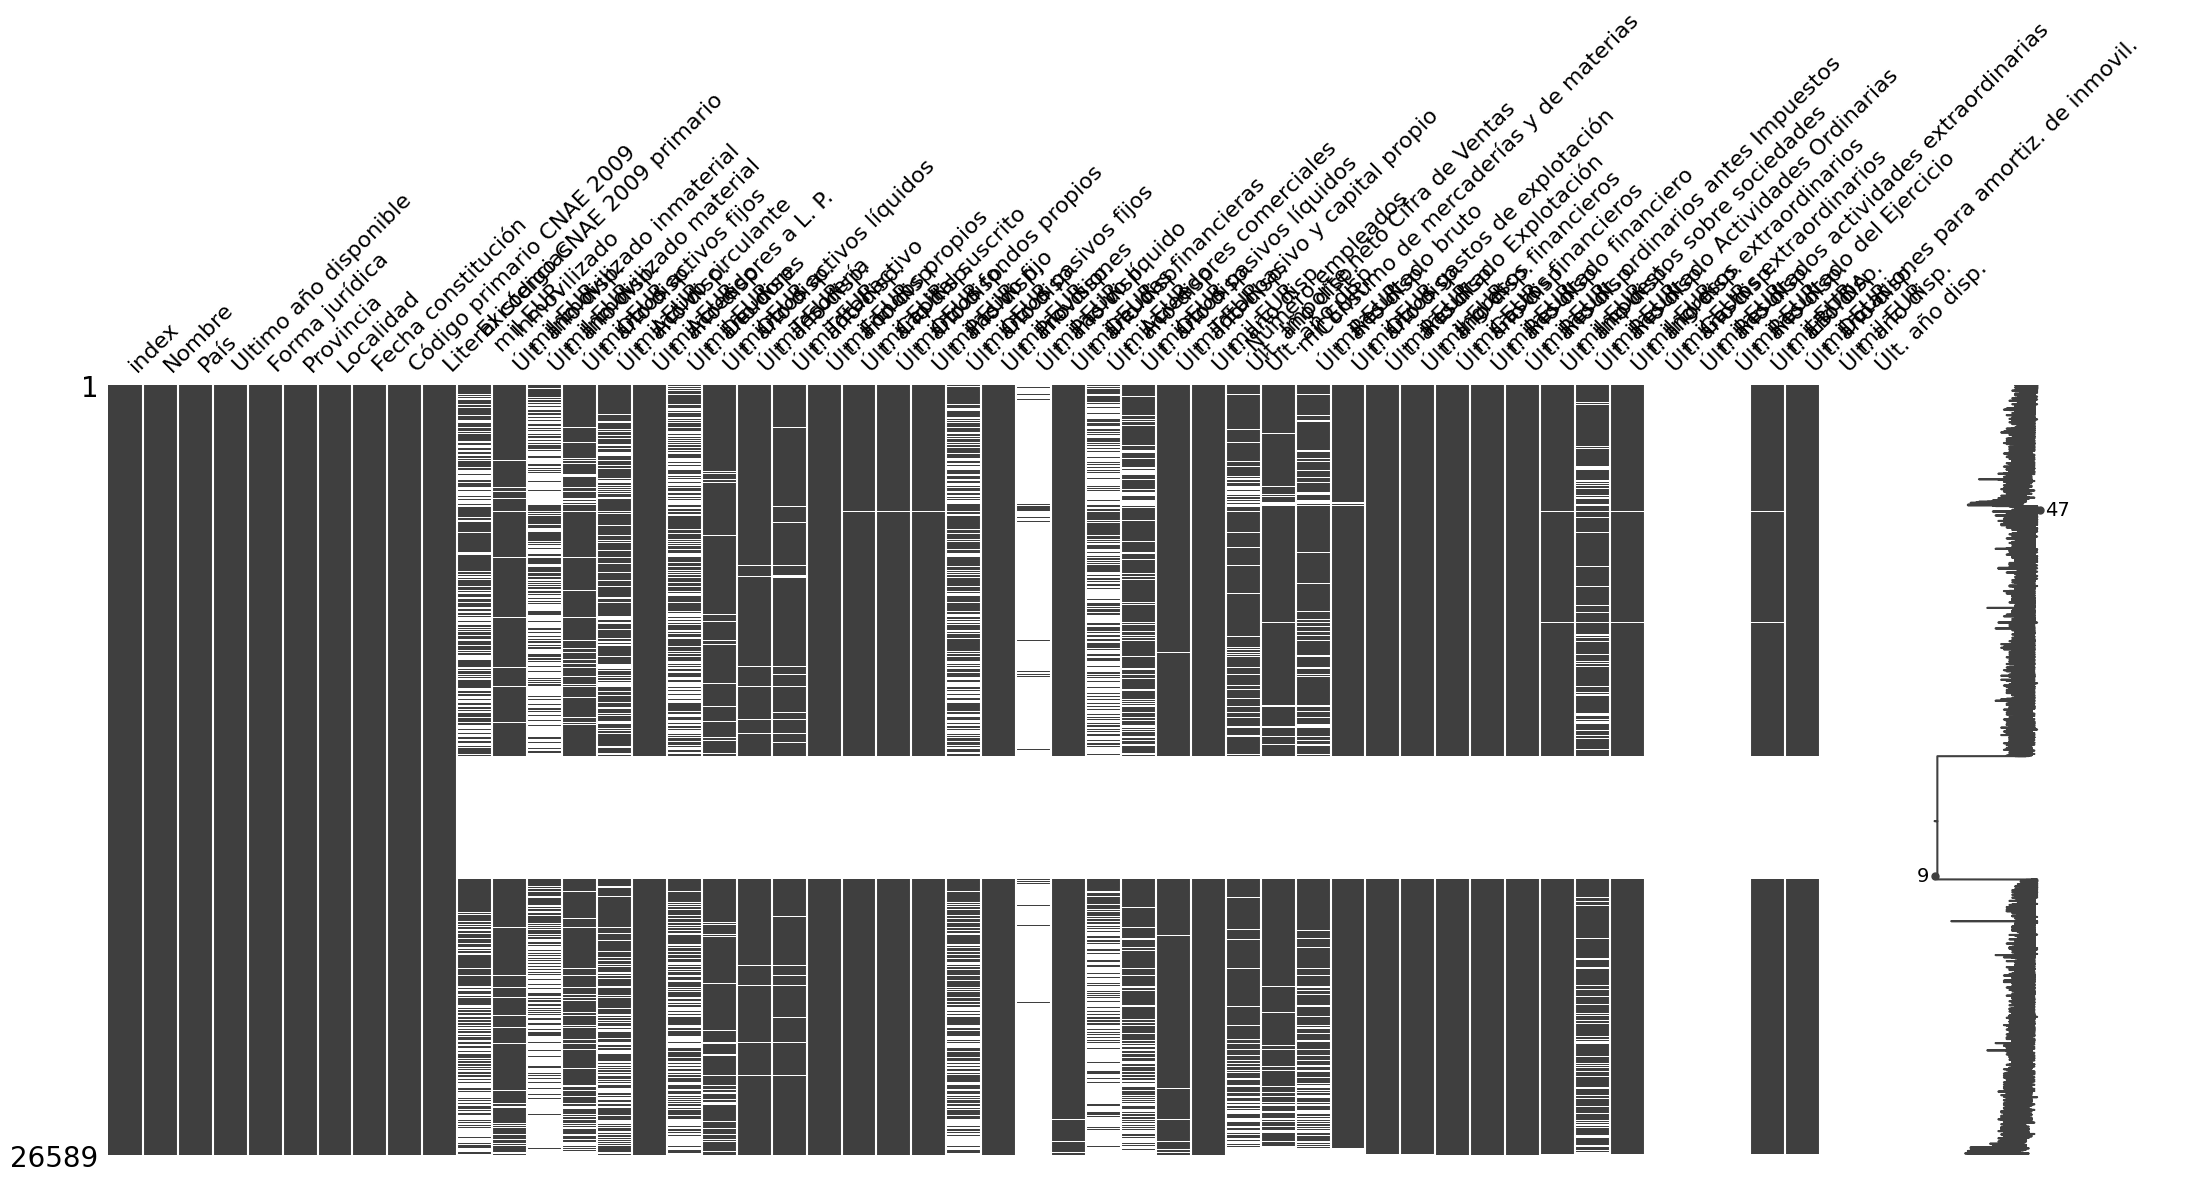

In [11]:
msno.matrix(df)  # para visualizar los nulos. hay una gran cantidad en varias columnas. 
# primero intento imputar usando las fórmulas y otras variables.

In [12]:
df.columns

Index(['index', 'Nombre', 'País', 'Ultimo año disponible', 'Forma jurídica',
       'Provincia', 'Localidad', 'Fecha constitución',
       'Código primario CNAE 2009', 'Literal código CNAE 2009 primario',
       'Existencias\nmil EUR\nÚlt. año disp.',
       'Inmovilizado\nmil EUR\nÚlt. año disp.',
       'Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.',
       'Inmovilizado material\nmil EUR\nÚlt. año disp.',
       'Otros activos fijos\nmil EUR\nÚlt. año disp.',
       'Activo circulante\nmil EUR\nÚlt. año disp.',
       'Acreedores a L. P.\nmil EUR\nÚlt. año disp.',
       'Deudores\nmil EUR\nÚlt. año disp.',
       'Otros activos líquidos\nmil EUR\nÚlt. año disp.',
       'Tesorería\nmil EUR\nÚlt. año disp.',
       'Total activo\nmil EUR\nÚlt. año disp.',
       'Fondos propios\nmil EUR\nÚlt. año disp.',
       'Capital suscrito\nmil EUR\nÚlt. año disp.',
       'Otros fondos propios\nmil EUR\nÚlt. año disp.',
       'Pasivo fijo\nmil EUR\nÚlt. año disp.',
       'Otros pasivos 

## Identificar outliers en las variables indicadas

CÓDIGO CNAE 2009

In [13]:
Q1 = df["Código primario CNAE 2009"].quantile(0.25)
Q3 = df["Código primario CNAE 2009"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(lower_bound)
print(upper_bound)

575.0
10567.0


<Axes: >

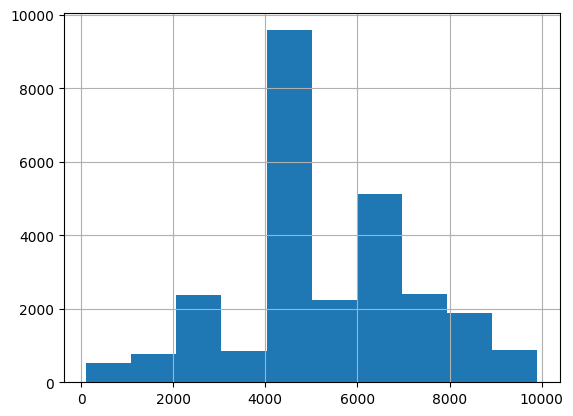

In [14]:
outliers = ((df["Código primario CNAE 2009"] < lower_bound) | (df["Código primario CNAE 2009"] > upper_bound))
df["Código primario CNAE 2009"].hist()

In [15]:
outliers_valores = df["Código primario CNAE 2009"][
    (df["Código primario CNAE 2009"] < Q1 - 1.5 * IQR) | 
    (df["Código primario CNAE 2009"] > Q3 + 1.5 * IQR)
]

print(outliers_valores)

# no tiene sentido imputar porque son códigos sobre a qué se dedica cada empresa

131      113
212      220
281      125
282      111
412      121
        ... 
25867    161
25870    210
26063    147
26115    161
26118    143
Name: Código primario CNAE 2009, Length: 264, dtype: int64


FECHA CONSTITUCION

In [16]:
df["año"] = pd.to_datetime(df["Fecha constitución"], dayfirst=True, errors="coerce").dt.year

C:\Users\nahia\AppData\Local\Temp\ipykernel_20896\857742171.py:1: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["año"] = pd.to_datetime(df["Fecha constitución"], dayfirst=True, errors="coerce").dt.year


In [17]:
df["año"].isna().value_counts()

año
False    26579
True        10
Name: count, dtype: int64

In [18]:
df = df.dropna(subset=["año"])

In [19]:
df["año"]= pd.to_numeric(df["año"])

In [20]:
# IQR
q1 = df["año"].quantile(0.25)
q3 = df["año"].quantile(0.75)
iqr = q3 - q1


limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

In [21]:
mediana = df['año'].median()
outliers = ((df['año'] < limite_inferior) | (df['año'] > limite_superior))

In [22]:
outliers

0         True
1        False
2         True
3        False
4        False
         ...  
26584    False
26585    False
26586    False
26587    False
26588    False
Name: año, Length: 26579, dtype: bool

<Axes: >

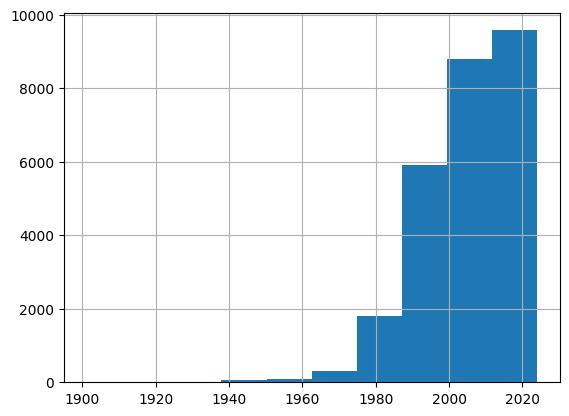

In [23]:
df['año'].hist(bins=10)

NUMERO EMPLEADOS

In [24]:
df["Número empleados\nÚlt. año disp."] = df["Número empleados\nÚlt. año disp."].astype('Int64') 
# cambio esto porque estaba en float

Q1 = df["Número empleados\nÚlt. año disp."].quantile(0.25)
Q3 = df["Número empleados\nÚlt. año disp."].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(lower_bound)
print(upper_bound)

-14.5
29.5


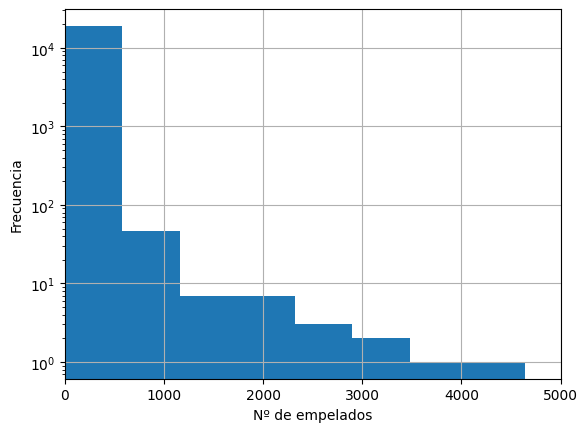

In [25]:
outliers = ((df["Número empleados\nÚlt. año disp."] < lower_bound) | (df["Número empleados\nÚlt. año disp."] > upper_bound))
df["Número empleados\nÚlt. año disp."].hist(bins=50, log=True)  #pongo log porque hay outliers grandes y sino no se ve bien la diferencia graficamente
plt.xlim(0, 5000)
plt.xlabel("Nº de empelados")
plt.ylabel("Frecuencia")
plt.show()

In [26]:
outliers_valores = df["Número empleados\nÚlt. año disp."][
    (df["Número empleados\nÚlt. año disp."] < Q1 - 1.5 * IQR) | 
    (df["Número empleados\nÚlt. año disp."] > Q3 + 1.5 * IQR)
]

print(outliers_valores.max())
df.loc[df["Número empleados\nÚlt. año disp."] == 28975]

28975


,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Ingresos extraordinarios\nmil EUR\nÚlt. año disp.,Gastos extraordinarios\nmil EUR\nÚlt. año disp.,Resultados actividades extraordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.,año
4198,6102,EULEN SOCIEDAD ANONIMA,ESPANA,2024-12-31,Sociedad anonima,Vizcaya,BILBAO,1978-04-19 00:00:00,8122,Otras actividades de limpieza industrial y de ...,...,8927.0,-2669.0,11596.0,NaN,NaN,NaN,11596.0,20461.0,NaN,1978.0


In [27]:
df[df["Número empleados\nÚlt. año disp."] <= 0]  #no hay valores negativos ni igual a 0

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Ingresos extraordinarios\nmil EUR\nÚlt. año disp.,Gastos extraordinarios\nmil EUR\nÚlt. año disp.,Resultados actividades extraordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.,año


## FORMULAS PARA NULOS

In [28]:
#ACTIVO CIRCULANTE
activo="Activo circulante\nmil EUR\nÚlt. año disp."
col1="Existencias\nmil EUR\nÚlt. año disp."
col2="Deudores\nmil EUR\nÚlt. año disp."
col3="Otros activos líquidos\nmil EUR\nÚlt. año disp."
col4="Tesorería\nmil EUR\nÚlt. año disp."

variables= [col1,col2,col3,col4,activo]

for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    #uso pd.isna porque con el loc me da un valor unico y isna no se puede con eso
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] - df.loc[i, col2] - df.loc[i, col3] - df.loc[i, col4]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, activo] - df.loc[i, col1] - df.loc[i, col3] - df.loc[i, col4]

    if pd.isna(df.loc[i, col3]):
        df.loc[i, col3] = df.loc[i, activo] - df.loc[i, col1] - df.loc[i, col2] - df.loc[i, col4]

    if pd.isna(df.loc[i, col4]):
        df.loc[i, col4] = df.loc[i, activo] - df.loc[i, col1] - df.loc[i, col2] - df.loc[i, col3]

    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] + df.loc[i, col2] + df.loc[i, col3] + df.loc[i, col4]

df.isna().sum()  # ahora hay menos nulos en existencias



index                                                                  0
Nombre                                                                 0
País                                                                   0
Ultimo año disponible                                                  0
Forma jurídica                                                         0
Provincia                                                              0
Localidad                                                              1
Fecha constitución                                                     0
Código primario CNAE 2009                                              0
Literal código CNAE 2009 primario                                      0
Existencias\nmil EUR\nÚlt. año disp.                                5255
Inmovilizado\nmil EUR\nÚlt. año disp.                               5244
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                   18465
Inmovilizado material\nmil EUR\nÚlt. año disp.     

In [29]:
#INMOVILIZADO
activo="Inmovilizado\nmil EUR\nÚlt. año disp."
col1="Inmovilizado inmaterial\nmil EUR\nÚlt. año disp."
col2="Inmovilizado material\nmil EUR\nÚlt. año disp."
col3="Otros activos fijos\nmil EUR\nÚlt. año disp."


variables= [col1,col2,col3,activo]

for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    #uso pd.isna porque con el loc me da un valor unico y isna no se puede con eso
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] - df.loc[i, col2] - df.loc[i, col3]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, activo] - df.loc[i, col1] - df.loc[i, col3] 

    if pd.isna(df.loc[i, col3]):
        df.loc[i, col3] = df.loc[i, activo] - df.loc[i, col1] - df.loc[i, col2] 

    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] + df.loc[i, col2] + df.loc[i, col3] 



In [30]:
# PASIVO Y CAPITAL PROPIO
activo="Total pasivo y capital propio\nmil EUR\nÚlt. año disp."
col1="Total activo\nmil EUR\nÚlt. año disp."
col2="Capital suscrito\nmil EUR\nÚlt. año disp."


variables= [col1,col2,activo]

for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    #uso pd.isna porque con el loc me da un valor unico y isna no se puede con eso
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] + df.loc[i, col2] 

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, col1]-df.loc[i, activo]  

    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] - df.loc[i, col2] 



In [31]:

#Total activo:
total_activo="Total activo\nmil EUR\nÚlt. año disp."
col1="Inmovilizado\nmil EUR\nÚlt. año disp."
col2="Activo circulante\nmil EUR\nÚlt. año disp."

variables= [col1,col2,total_activo]
for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, total_activo] - df.loc[i, col2]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, total_activo] - df.loc[i, col1]

    if pd.isna(df.loc[i, total_activo]):
        df.loc[i, total_activo] = df.loc[i, col1] + df.loc[i, col2]


In [32]:

#Fondos PROPIOS:
activo="Fondos propios\nmil EUR\nÚlt. año disp."
col1="Capital suscrito\nmil EUR\nÚlt. año disp."
col2="Otros fondos propios\nmil EUR\nÚlt. año disp."

variables= [col1,col2,activo]
for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] - df.loc[i, col2]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, activo] - df.loc[i, col1]

    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] + df.loc[i, col2]


In [33]:

#PASIVO FIJO
pasivo = "Pasivo fijo\nmil EUR\nÚlt. año disp."
col1 = "Acreedores a L. P.\nmil EUR\nÚlt. año disp."
col2 = "Otros pasivos fijos\nmil EUR\nÚlt. año disp."
col3 = "Provisiones\nmil EUR\nÚlt. año disp."


variables = [col1,col2,col3, pasivo]
for i in df.index:


    if df.loc[i, variables].isna().sum() > 1:
        continue
    #uso pd.isna porque con el loc me da un valor unico y isna no se puede con eso
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, pasivo] - df.loc[i, col2] - df.loc[i, col3]


    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, pasivo] - df.loc[i, col1] - df.loc[i, col3]


    if pd.isna(df.loc[i, col3]):
        df.loc[i, col3] = df.loc[i, pasivo] - df.loc[i, col1] - df.loc[i, col2]


    if pd.isna(df.loc[i, pasivo]):
        df.loc[i, pasivo] = df.loc[i, col1] + df.loc[i, col2] + df.loc[i, col3]


In [34]:

#Pasivo líquido:
activo="Pasivo líquido\nmil EUR\nÚlt. año disp."
col1="Deudas financieras\nmil EUR\nÚlt. año disp."
col2="Acreedores comerciales\nmil EUR\nÚlt. año disp."
col3="Otros pasivos líquidos\nmil EUR\nÚlt. año disp."

variables= [col1,col2,col3,activo]

for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    #uso pd.isna porque con el loc me da un valor unico y isna no se puede con eso
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] - df.loc[i, col2] - df.loc[i, col3]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, activo] - df.loc[i, col1] - df.loc[i, col3]

    if pd.isna(df.loc[i, col3]):
        df.loc[i, col3] = df.loc[i, activo] - df.loc[i, col1] - df.loc[i, col2]

    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] + df.loc[i, col2] + df.loc[i, col3]



In [35]:
#TOTAL PASIVO Y CAPITAL PROPIO

activo="Total pasivo y capital propio\nmil EUR\nÚlt. año disp."
col1="Total activo\nmil EUR\nÚlt. año disp."
col2="Capital suscrito\nmil EUR\nÚlt. año disp."

variables= [col1,col2,activo]

for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    #uso pd.isna porque con el loc me da un valor unico y isna no se puede con eso
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] + df.loc[i, col2]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, col1]-df.loc[i, activo]  

    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] - df.loc[i, col2]


In [36]:

#RESULTADO BRUTO

activo="Resultado bruto\nmil EUR\nÚlt. año disp."
col1="Importe neto Cifra de Ventas\nmil EUR\nÚlt. año disp."
col2="Consumo de mercaderías y de materias\nmil EUR\nÚlt. año disp."

variables= [col1,col2,activo]

for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] + df.loc[i, col2]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, col1]-df.loc[i, activo]  

    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] - df.loc[i, col2]


In [37]:

#Resultado explotación:
r_explotacion="Resultado Explotación\nmil EUR\nÚlt. año disp."
col1="Resultado bruto\nmil EUR\nÚlt. año disp."
col2="Otros gastos de explotación\nmil EUR\nÚlt. año disp."

variables= [col1,col2,r_explotacion]
for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue   
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, r_explotacion] + df.loc[i, col2]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, col1] - df.loc[i, r_explotacion]

    if pd.isna(df.loc[i, r_explotacion]):
        df.loc[i, r_explotacion] = df.loc[i, col1] - df.loc[i, col2]



In [38]:

#Resultado financiero:
activo="Resultado financiero\nmil EUR\nÚlt. año disp."
col1="Ingresos financieros\nmil EUR\nÚlt. año disp."
col2="Gastos financieros\nmil EUR\nÚlt. año disp."

variables= [col1,col2,activo]

for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue

    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, activo] - df.loc[i, col2]
        
    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, activo] + df.loc[i, col1]
    
    if pd.isna(df.loc[i, activo]):
        df.loc[i, activo] = df.loc[i, col1] - df.loc[i, col2]



In [39]:

#RESULTADOS ORDINARIOS ANTES DE IMPUESTOS
pasivo = "Pasivo fijo\nmil EUR\nÚlt. año disp."
col1 = 'Resultado Explotación\nmil EUR\nÚlt. año disp.'
col2 = "Resultado financiero\nmil EUR\nÚlt. año disp."

variables = [col1,col2, pasivo]
for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
    
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, pasivo] - df.loc[i, col2]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, pasivo] - df.loc[i, col1]

    if pd.isna(df.loc[i, pasivo]):
        df.loc[i, pasivo] = df.loc[i, col1] + df.loc[i, col2]


In [40]:

# RESULTADOS ORDINARIOS ANTES DE IMPUESTOS

pasivo = 'Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.'
col1 = 'Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.'
col2 = 'Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.'


variables= [col1, col2, pasivo]

for i in df.index:
    
    if df.loc[i, variables].isna().sum() > 1:
        continue

    # Calcular resultado actividades ordinarias (col1)
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, pasivo] + df.loc[i, col2]

    # Calcular impuestos (col2)
    if  pd.isna(df.loc[i, col2]):
     df.loc[i, col2] = df.loc[i, col1] - df.loc[i, pasivo]

     if pd.isna(df.loc[i, pasivo]):
        df.loc[i, pasivo] = df.loc[i, col1] - df.loc[i, col2]



In [41]:

# RESULTADOS DE EJERCICIO

pasivo = 'Resultado del Ejercicio\nmil EUR\nÚlt. año disp.'
col1= 'Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.'
col2 = 'Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.'


variables= [col1, col2, pasivo]

for i in df.index:
    
    if df.loc[i, variables].isna().sum() > 1:
        continue

    # Calcular resultado actividades ordinarias (col1)
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, pasivo] - df.loc[i, col2]

    # Calcular impuestos (col2)
    if  pd.isna(df.loc[i, col2]):
     df.loc[i, col2] = df.loc[i, pasivo] - df.loc[i, col1]

     if pd.isna(df.loc[i, pasivo]):
        df.loc[i, pasivo] = df.loc[i, col1] + df.loc[i, col2]


In [42]:

#EBITDA
ebitda="EBITDA\nmil EUR\nÚlt. año disp."
col1="Resultado Explotación\nmil EUR\nÚlt. año disp."
col2="Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp."

variables= [col1,col2,ebitda]
for i in df.index:

    if df.loc[i, variables].isna().sum() > 1:
        continue
   
    if pd.isna(df.loc[i, col1]):
        df.loc[i, col1] = df.loc[i, ebitda] - df.loc[i, col2]

    if pd.isna(df.loc[i, col2]):
        df.loc[i, col2] = df.loc[i, ebitda] - df.loc[i, col1]

    if pd.isna(df.loc[i, ebitda]):
        df.loc[i, ebitda] = df.loc[i, col1] + df.loc[i, col2]



In [43]:
df.isna().mean()*100

index                                                                0.000000
Nombre                                                               0.000000
País                                                                 0.000000
Ultimo año disponible                                                0.000000
Forma jurídica                                                       0.000000
Provincia                                                            0.000000
Localidad                                                            0.003762
Fecha constitución                                                   0.000000
Código primario CNAE 2009                                            0.000000
Literal código CNAE 2009 primario                                    0.000000
Existencias\nmil EUR\nÚlt. año disp.                                19.771248
Inmovilizado\nmil EUR\nÚlt. año disp.                               16.016404
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                

## IMPUTAR (info externa, 0, mediana y por sector)

In [44]:
df = df.drop(["Ingresos extraordinarios\nmil EUR\nÚlt. año disp.", "Gastos extraordinarios\nmil EUR\nÚlt. año disp.", "Resultados actividades extraordinarias\nmil EUR\nÚlt. año disp."], axis=1)
#dropeo las columnas con 100% o 99% de nulos porque son extraordinarias y no me aporta info

In [45]:
# rellenamos los nulos que se pueden (son pocos y están en internet)

# 1. en localidad
df[df["Localidad"].isna()]

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Ingresos financieros\nmil EUR\nÚlt. año disp.,Gastos financieros\nmil EUR\nÚlt. año disp.,Resultado financiero\nmil EUR\nÚlt. año disp.,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.,año
18510,27532,MOSNIC-IRUDEX SL,ESPANA,2024-12-31,Sociedad limitada,Guipuzcoa,NaN,2008-04-09 00:00:00,2849,Fabricación de otras máquinas herramienta,...,0.0,15.82122,-15.82122,42.65234,5.24023,37.41211,37.41211,95.06215,0.0,2008.0


In [46]:
df.loc[df["Localidad"].isna(), "Localidad"] = "Deba"
df[df["Localidad"].isna()]

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Ingresos financieros\nmil EUR\nÚlt. año disp.,Gastos financieros\nmil EUR\nÚlt. año disp.,Resultado financiero\nmil EUR\nÚlt. año disp.,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.,año


In [47]:
#2. en fecha
df[df["Fecha constitución"].isna()]

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Ingresos financieros\nmil EUR\nÚlt. año disp.,Gastos financieros\nmil EUR\nÚlt. año disp.,Resultado financiero\nmil EUR\nÚlt. año disp.,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.,año


In [48]:
fechas = [
    "24-11-1846",
    "23-03-2021",
    "22-07-1991",
    "19-11-2014",
    "22-02-2017",
    "18-01-1962"
]  #estas fechas las hemos buscado en internet (correspondientes a cada empresa)

nulos = df["Fecha constitución"].isna()
df.loc[nulos, "Fecha constitución"] = fechas[:nulos.sum()]  


In [49]:
df[df["Fecha constitución"].isna()]

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Ingresos financieros\nmil EUR\nÚlt. año disp.,Gastos financieros\nmil EUR\nÚlt. año disp.,Resultado financiero\nmil EUR\nÚlt. año disp.,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.,año


In [50]:
df.isna().mean()*100

index                                                             0.000000
Nombre                                                            0.000000
País                                                              0.000000
Ultimo año disponible                                             0.000000
Forma jurídica                                                    0.000000
Provincia                                                         0.000000
Localidad                                                         0.000000
Fecha constitución                                                0.000000
Código primario CNAE 2009                                         0.000000
Literal código CNAE 2009 primario                                 0.000000
Existencias\nmil EUR\nÚlt. año disp.                             19.771248
Inmovilizado\nmil EUR\nÚlt. año disp.                            16.016404
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                 39.064675
Inmovilizado material\nmi

In [51]:
# hay columnas que tiene sentido que sean 0 y por eso no tienen información disponible. 
# por eso sustituimos sus nas por 0. nos hemos fijado en el porcentaje de nas que tenian las columnas.
    # acreedores a lp y provisiones parece que hay muchos no reportados por la cantidad de nulos que hay
cols_cero = [
"Acreedores a L. P.\nmil EUR\nÚlt. año disp.",
"Otros pasivos líquidos\nmil EUR\nÚlt. año disp.",
"Otros pasivos fijos\nmil EUR\nÚlt. año disp.",
"Provisiones\nmil EUR\nÚlt. año disp.",
"Ingresos financieros\nmil EUR\nÚlt. año disp.",
"Gastos financieros\nmil EUR\nÚlt. año disp.",
"Consumo de mercaderías y de materias\nmil EUR\nÚlt. año disp.",
"Otros gastos de explotación\nmil EUR\nÚlt. año disp.",
"Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp."
]

df[cols_cero] = df[cols_cero].fillna(0)

df.isna().mean()*100

index                                                             0.000000
Nombre                                                            0.000000
País                                                              0.000000
Ultimo año disponible                                             0.000000
Forma jurídica                                                    0.000000
Provincia                                                         0.000000
Localidad                                                         0.000000
Fecha constitución                                                0.000000
Código primario CNAE 2009                                         0.000000
Literal código CNAE 2009 primario                                 0.000000
Existencias\nmil EUR\nÚlt. año disp.                             19.771248
Inmovilizado\nmil EUR\nÚlt. año disp.                            16.016404
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                 39.064675
Inmovilizado material\nmi

separar por cnae para imputar por mediana según sector:


In [52]:
df["sector"] = df["Código primario CNAE 2009"].astype(str).str[:2]
df.head()

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,Gastos financieros\nmil EUR\nÚlt. año disp.,Resultado financiero\nmil EUR\nÚlt. año disp.,Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.,Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.,Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.,Resultado del Ejercicio\nmil EUR\nÚlt. año disp.,EBITDA\nmil EUR\nÚlt. año disp.,Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.,año,sector
0,0,"VIDRALA, SA",ESPANA,2024-12-31,Sociedad anonima,Alava,LAUDIO/LLODIO,1965-03-17 00:00:00,2313,Fabricación de vidrio hueco,...,15765.0,81676.0,166764.0,19799.0,146965.0,146965.0,87847.0,0.0,1965.0,23
1,1,AERNNOVA AEROSPACE SA,ESPANA,2024-12-31,Sociedad anonima,Alava,VITORIA-GASTEIZ,1999-07-19 00:00:00,3030,Construcción aeronáutica y espacial y su maqui...,...,56676.0,-33228.0,13070.0,4291.0,8779.0,8779.0,48818.0,0.0,1999.0,30
2,3,COMPAÑIA DE BEBIDAS PEPSICO SL,ESPANA,2024-12-31,Sociedad limitada,Alava,VITORIA-GASTEIZ,1957-09-04 00:00:00,1107,Fabricación de bebidas no alcohólicas; producc...,...,40114.0,-12304.0,52302.0,-10390.0,62692.0,62692.0,71344.0,0.0,1957.0,11
3,4,ARRAIA-OIL SL,ESPANA,2024-12-31,Sociedad limitada,Alava,VITORIA-GASTEIZ,2001-01-21 00:00:00,4730,Comercio al por menor de combustible para la a...,...,314.0,-57.0,5280.0,1490.0,3790.0,3790.0,6572.0,0.0,2001.0,47
4,6,"TUBOS REUNIDOS GROUP, S.L.",ESPANA,2024-12-31,Sociedad limitada,Alava,AMURRIO,2010-01-04 00:00:00,2420,"Fabricación de tubos, tuberías, perfiles hueco...",...,19151.0,-16478.0,-12522.0,-8438.0,-4084.0,-4084.0,18930.0,0.0,2010.0,24


In [53]:
df["sector"].unique()

<StringArray>
['23', '30', '11', '47', '24', '10', '46', '62', '52', '64', '38', '22', '25',
 '35', '29', '66', '68', '41', '71', '93', '42', '20', '45', '49', '28', '32',
 '27', '18', '86', '81', '36', '82', '77', '43', '55', '17', '26', '78', '73',
 '16', '74', '72', '69', '12', '58', '13', '31', '88', '21', '70', '61', '14',
 '89', '80', '33', '56', '94', '85', '96', '53', '87', '92', '51', '79', '90',
 '84', '59', '95', '75', '39', '15', '99', '63', '60', '65', '91', '19', '50',
 '37']
Length: 79, dtype: str

In [54]:
#lo primero que vamos a hacer es crear una variable con todas las columnas que queremos imputar

columnas = ["Existencias\nmil EUR\nÚlt. año disp.","Inmovilizado\nmil EUR\nÚlt. año disp.",

"Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.",

"Inmovilizado material\nmil EUR\nÚlt. año disp.",

"Otros activos fijos\nmil EUR\nÚlt. año disp.",

"Activo circulante\nmil EUR\nÚlt. año disp.",

"Acreedores a L. P.\nmil EUR\nÚlt. año disp.",

"Deudores\nmil EUR\nÚlt. año disp.",

"Otros activos líquidos\nmil EUR\nÚlt. año disp.",

"Total activo\nmil EUR\nÚlt. año disp.",

"Fondos propios\nmil EUR\nÚlt. año disp.",

"Capital suscrito\nmil EUR\nÚlt. año disp.",

"Otros fondos propios\nmil EUR\nÚlt. año disp.",

"Pasivo fijo\nmil EUR\nÚlt. año disp.",

"Otros pasivos fijos\nmil EUR\nÚlt. año disp.",

"Provisiones\nmil EUR\nÚlt. año disp.",

"Pasivo líquido\nmil EUR\nÚlt. año disp.",

"Acreedores comerciales\nmil EUR\nÚlt. año disp.",

"Otros pasivos líquidos\nmil EUR\nÚlt. año disp.",

"Total pasivo y capital propio\nmil EUR\nÚlt. año disp.",

"Número empleados\nÚlt. año disp.",

"Importe neto Cifra de Ventas\nmil EUR\nÚlt. año disp.",

"Consumo de mercaderías y de materias\nmil EUR\nÚlt. año disp.",

"Resultado bruto\nmil EUR\nÚlt. año disp.",

"Otros gastos de explotación\nmil EUR\nÚlt. año disp.",

"Resultado Explotación\nmil EUR\nÚlt. año disp.",

"Ingresos financieros\nmil EUR\nÚlt. año disp.",

"Gastos financieros\nmil EUR\nÚlt. año disp.",

"Resultado financiero\nmil EUR\nÚlt. año disp.",

"Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.",

"Impuestos sobre sociedades\nmil EUR\nÚlt. año disp.",

"Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.",

"Resultado del Ejercicio\nmil EUR\nÚlt. año disp.",

"Dotaciones para amortiz. de inmovil.\nmil EUR\nÚlt. año disp.",

"sector"]


In [55]:
df.dtypes

index                                                              int64
Nombre                                                               str
País                                                                 str
Ultimo año disponible                                                str
Forma jurídica                                                       str
Provincia                                                            str
Localidad                                                            str
Fecha constitución                                                   str
Código primario CNAE 2009                                          int64
Literal código CNAE 2009 primario                                    str
Existencias\nmil EUR\nÚlt. año disp.                             float64
Inmovilizado\nmil EUR\nÚlt. año disp.                            float64
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                 float64
Inmovilizado material\nmil EUR\nÚlt. año disp.     

In [56]:
for col in columnas:

    df[col] = df[col].astype(float)

    medianas = df.groupby("sector")[col].median()

    df[col] = df[col].fillna(df["sector"].map(medianas))



In [57]:
df.isna().mean()*100

index                                                             0.000000
Nombre                                                            0.000000
País                                                              0.000000
Ultimo año disponible                                             0.000000
Forma jurídica                                                    0.000000
Provincia                                                         0.000000
Localidad                                                         0.000000
Fecha constitución                                                0.000000
Código primario CNAE 2009                                         0.000000
Literal código CNAE 2009 primario                                 0.000000
Existencias\nmil EUR\nÚlt. año disp.                              0.000000
Inmovilizado\nmil EUR\nÚlt. año disp.                             0.000000
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                  0.000000
Inmovilizado material\nmi

## RANDOM FOREST

In [58]:
columnas2=df[["Deudas financieras\nmil EUR\nÚlt. año disp.", "EBITDA\nmil EUR\nÚlt. año disp.","Tesorería\nmil EUR\nÚlt. año disp."]]
#como estas consideramos que son variables importantes queremos mas precision --> random forest

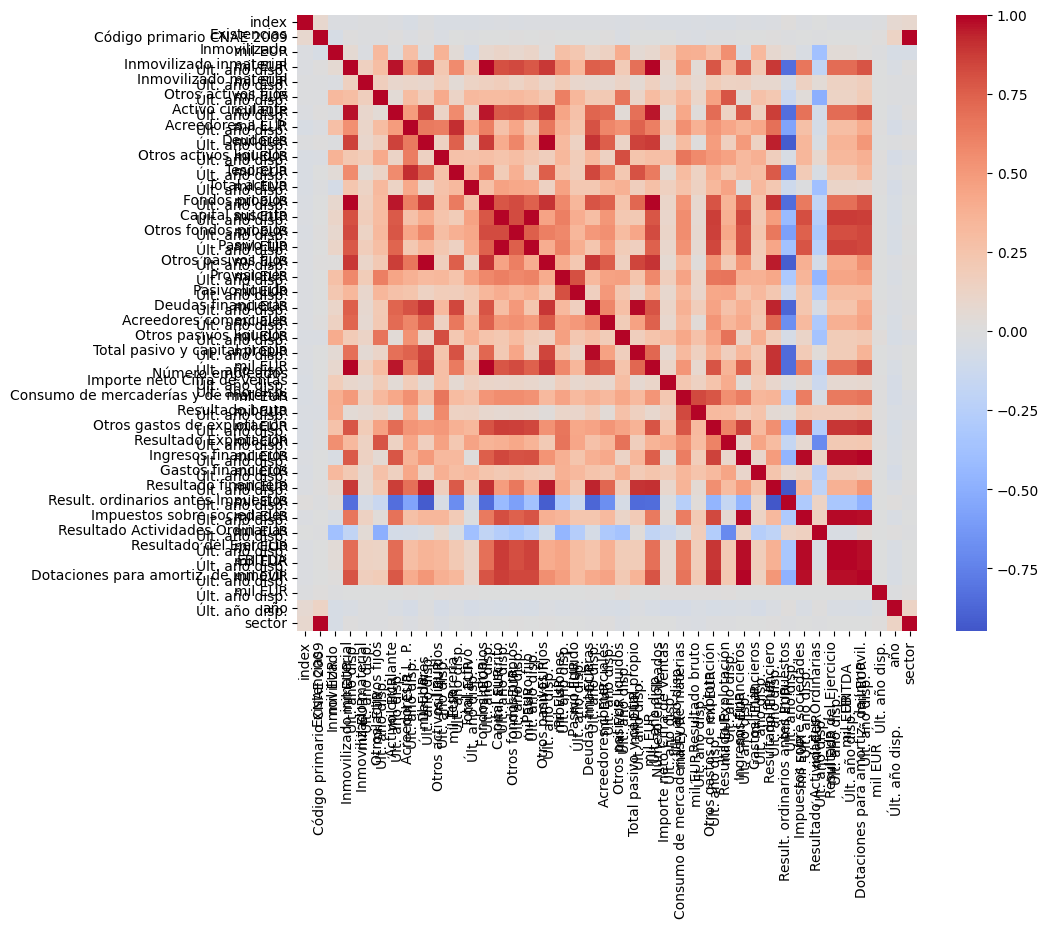

In [59]:
#lo primero de todo es realizar una matriz de correlacion para ver las relaciones entre las variables del dataframe con las que vamos a querer imputar


plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.show()

In [60]:
#como la matriz de correlacion no nos muestra nada vamos a ir mirando las correlaciones de las columnas que queremos calcular uno por una
df.corr(numeric_only=True)["EBITDA\nmil EUR\nÚlt. año disp."].sort_values(ascending=False).head(10)

EBITDA\nmil EUR\nÚlt. año disp.                                1.000000
Resultado Explotación\nmil EUR\nÚlt. año disp.                 0.989690
Resultado Actividades Ordinarias\nmil EUR\nÚlt. año disp.      0.974050
Resultado del Ejercicio\nmil EUR\nÚlt. año disp.               0.974050
Result. ordinarios antes Impuestos\nmil EUR\nÚlt. año disp.    0.969702
Resultado bruto\nmil EUR\nÚlt. año disp.                       0.910052
Fondos propios\nmil EUR\nÚlt. año disp.                        0.867469
Otros fondos propios\nmil EUR\nÚlt. año disp.                  0.837789
Capital suscrito\nmil EUR\nÚlt. año disp.                      0.835278
Inmovilizado\nmil EUR\nÚlt. año disp.                          0.794495
Name: EBITDA\nmil EUR\nÚlt. año disp., dtype: float64

In [61]:
df.corr(numeric_only=True)["Deudas financieras\nmil EUR\nÚlt. año disp."].sort_values(ascending=False).head(10)

Deudas financieras\nmil EUR\nÚlt. año disp.               1.000000
Pasivo fijo\nmil EUR\nÚlt. año disp.                      0.761368
Acreedores a L. P.\nmil EUR\nÚlt. año disp.               0.751386
Total activo\nmil EUR\nÚlt. año disp.                     0.748238
Total pasivo y capital propio\nmil EUR\nÚlt. año disp.    0.748238
Inmovilizado\nmil EUR\nÚlt. año disp.                     0.731885
Gastos financieros\nmil EUR\nÚlt. año disp.               0.724802
Otros activos fijos\nmil EUR\nÚlt. año disp.              0.710202
Otros activos líquidos\nmil EUR\nÚlt. año disp.           0.644112
Pasivo líquido\nmil EUR\nÚlt. año disp.                   0.587254
Name: Deudas financieras\nmil EUR\nÚlt. año disp., dtype: float64

In [62]:
df.corr(numeric_only=True)["Tesorería\nmil EUR\nÚlt. año disp."].sort_values(ascending=False).head(10)

Tesorería\nmil EUR\nÚlt. año disp.                      1.000000
Fondos propios\nmil EUR\nÚlt. año disp.                 0.459828
Otros pasivos fijos\nmil EUR\nÚlt. año disp.            0.453883
Otros gastos de explotación\nmil EUR\nÚlt. año disp.    0.449445
Capital suscrito\nmil EUR\nÚlt. año disp.               0.422326
Activo circulante\nmil EUR\nÚlt. año disp.              0.415372
Otros fondos propios\nmil EUR\nÚlt. año disp.           0.413929
Acreedores comerciales\nmil EUR\nÚlt. año disp.         0.374673
Deudas financieras\nmil EUR\nÚlt. año disp.             0.335506
Resultado bruto\nmil EUR\nÚlt. año disp.                0.333658
Name: Tesorería\nmil EUR\nÚlt. año disp., dtype: float64

In [ ]:
#ahora vamos a realizar los modelos random forest para terminar de imputar todos los datos

In [64]:
train = df[df["EBITDA\nmil EUR\nÚlt. año disp."].notna()]
test = df[df["EBITDA\nmil EUR\nÚlt. año disp."].isna()]

In [65]:
df_train = df[df["EBITDA\nmil EUR\nÚlt. año disp."].notna()]
df_test = df[df["EBITDA\nmil EUR\nÚlt. año disp."].isna()]

X_train = df_train[["Resultado Explotación\nmil EUR\nÚlt. año disp.", "Fondos propios\nmil EUR\nÚlt. año disp.", "Inmovilizado\nmil EUR\nÚlt. año disp."]]
y_train = df_train["EBITDA\nmil EUR\nÚlt. año disp."]

X_test = test[["Resultado Explotación\nmil EUR\nÚlt. año disp.", "Fondos propios\nmil EUR\nÚlt. año disp.", "Inmovilizado\nmil EUR\nÚlt. año disp."]]

In [66]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [67]:
df.loc[df["EBITDA\nmil EUR\nÚlt. año disp."].isna(), "EBITDA\nmil EUR\nÚlt. año disp."] = rf.predict(X_test)

In [68]:
df["EBITDA\nmil EUR\nÚlt. año disp."].isna().mean()*100

np.float64(0.0)

In [69]:
train = df[df["Deudas financieras\nmil EUR\nÚlt. año disp."].notna()]
test = df[df["Deudas financieras\nmil EUR\nÚlt. año disp."].isna()]

In [70]:
df_train = df[df["Deudas financieras\nmil EUR\nÚlt. año disp."].notna()]
df_test = df[df["Deudas financieras\nmil EUR\nÚlt. año disp."].isna()]

X_train = df_train[["Pasivo fijo\nmil EUR\nÚlt. año disp.","Acreedores a L. P.\nmil EUR\nÚlt. año disp." ,"Total activo\nmil EUR\nÚlt. año disp." ]]
y_train = df_train["Deudas financieras\nmil EUR\nÚlt. año disp."]

X_test = test[["Pasivo fijo\nmil EUR\nÚlt. año disp.","Acreedores a L. P.\nmil EUR\nÚlt. año disp." ,"Total activo\nmil EUR\nÚlt. año disp." ]]

In [71]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [72]:
df.loc[df["Deudas financieras\nmil EUR\nÚlt. año disp."].isna(), "Deudas financieras\nmil EUR\nÚlt. año disp."] = rf.predict(X_test)

In [73]:
df["Deudas financieras\nmil EUR\nÚlt. año disp."].isna().mean()*100

np.float64(0.0)

In [74]:
# como tesorería no tiene mucha correlación con ninguna, imputamos con la mediana

In [75]:
df["Tesorería\nmil EUR\nÚlt. año disp."] = df["Tesorería\nmil EUR\nÚlt. año disp."].astype(float)

medianas = df.groupby("sector")[col].median()

df["Tesorería\nmil EUR\nÚlt. año disp."] = df["Tesorería\nmil EUR\nÚlt. año disp."].fillna(df["sector"].map(medianas))

In [76]:
df.isna().mean()*100

index                                                            0.0
Nombre                                                           0.0
País                                                             0.0
Ultimo año disponible                                            0.0
Forma jurídica                                                   0.0
Provincia                                                        0.0
Localidad                                                        0.0
Fecha constitución                                               0.0
Código primario CNAE 2009                                        0.0
Literal código CNAE 2009 primario                                0.0
Existencias\nmil EUR\nÚlt. año disp.                             0.0
Inmovilizado\nmil EUR\nÚlt. año disp.                            0.0
Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.                 0.0
Inmovilizado material\nmil EUR\nÚlt. año disp.                   0.0
Otros activos fijos\nmil EUR\nÚlt.

In [77]:
df.to_csv("df_limpio.csv", index=False)